# Week 3 - Self-Driving Car: Pre-processing, Batch Loading & the NVIDIA CNN

**Topics (record sections f, g, h)**
* f. Image pre-processing for deep learning regression
* g. Batch-loading the dataset with a Python generator
* h. NVIDIA's end-to-end CNN architecture

## Setup + recap of Week 2
This notebook is self-contained, so the cell below re-runs the load -> balance -> split steps from Weeks 1-2 (see those notebooks for explanations).

In [1]:
import os, random, ntpath, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cv2

from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, Dense, MaxPooling2D, Dropout, Flatten
from tensorflow.keras.optimizers import Adam

random.seed(0); np.random.seed(0); tf.random.set_seed(0)

datadir = "data/selfdrive"
if not os.path.exists(os.path.join(datadir, "driving_log.csv")):
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/Aman-py/data.git", datadir], check=True)
print("Dataset folder ready:", os.path.exists(datadir))

columns = ["center", "left", "right", "steering", "throttle", "reverse", "speed"]
dataset = pd.read_csv(os.path.join(datadir, "driving_log.csv"), names=columns)

# ---- Recap of Weeks 1-2: load -> clean paths -> balance -> split ----
num_bins, threshold = 25, 500

def removePath(path):
    return ntpath.split(path)[1]

for col in ["center", "left", "right"]:
    dataset[col] = dataset[col].apply(removePath)

hist, bins = np.histogram(dataset["steering"], num_bins)
bin_id = np.clip(np.digitize(dataset["steering"], bins[1:-1]), 0, num_bins - 1)   # each sample -> exactly one bin
remove_list = []
for i in range(num_bins):
    idx = shuffle(np.where(bin_id == i)[0], random_state=42)
    remove_list.extend(idx[threshold:])            # drop only the surplus above the threshold
dataset = dataset.drop(dataset.index[remove_list]).reset_index(drop=True)

def loadImageSteering(datadir, df):
    paths = [os.path.join(datadir, c) for c in df["center"]]
    return np.asarray(paths), df["steering"].astype(float).to_numpy()

imagePath, steeringPath = loadImageSteering(os.path.join(datadir, "IMG"), dataset)
x_train, x_test, y_train, y_test = train_test_split(imagePath, steeringPath, test_size=0.2, random_state=6)
baseline_mse = np.mean((y_test - np.mean(y_train)) ** 2)
print("Balanced dataset:", len(dataset), "| train:", len(x_train), "| test:", len(x_test))

Dataset folder ready: True
Balanced dataset: 2305 | train: 1844 | test: 461


## f. Image pre-processing
Each raw frame (160x320x3) is transformed before it reaches the network:

| Step | Why |
|---|---|
| Crop rows 60-135 | the sky and the car's bonnet carry no steering information |
| RGB -> YUV | the colour space used in NVIDIA's paper: Y = brightness, U/V = colour |
| Gaussian blur (3x3) | removes small noise |
| Resize to 200x66 | the input size the NVIDIA network expects (cv2 takes `(width, height)`) |
| Divide by 255 | scales pixel values to [0, 1] so training is stable |

In [2]:
def imagePreprocessing(img_path):
    img = mpimg.imread(img_path)                    # read image (RGB)
    img = img[60:135, :, :]                         # crop away sky and car bonnet
    img = cv2.cvtColor(img, cv2.COLOR_RGB2YUV)      # RGB -> YUV (as in NVIDIA's paper)
    img = cv2.GaussianBlur(img, (3, 3), 0)          # light denoising
    img = cv2.resize(img, (200, 66))                # NVIDIA input size (width, height)
    img = img / 255.0                               # scale pixels to [0, 1]
    return img

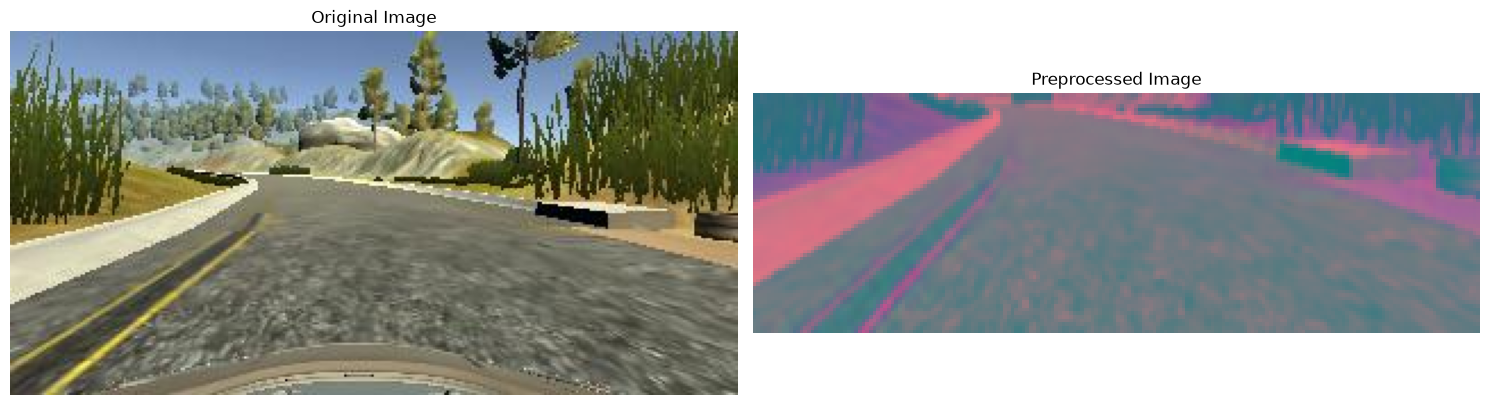

Original shape: (160, 320, 3)
Processed shape: (66, 200, 3) | value range: 0.02 - 0.92
Steering angle of this image: -0.1499941


In [3]:
sample_image = x_train[0]
original = mpimg.imread(sample_image)
processed = imagePreprocessing(sample_image)

fig, axs = plt.subplots(1, 2, figsize=(15, 6))
axs[0].imshow(original);  axs[0].set_title("Original Image");     axs[0].axis("off")
axs[1].imshow(processed); axs[1].set_title("Preprocessed Image"); axs[1].axis("off")
plt.tight_layout(); plt.show()

print("Original shape:", original.shape)
print("Processed shape:", processed.shape, "| value range:", processed.min().round(2), "-", processed.max().round(2))
print("Steering angle of this image:", y_train[0])

(The processed picture looks strange because it is displayed as if YUV were RGB - that is expected; the network does not care how it looks to humans.)

## g. Batch generator
Loading all images into RAM at once is wasteful. A **generator** produces one batch at a time:
1. shuffle the order of the data each epoch,
2. load + pre-process just `batch_size` images,
3. `yield` them as NumPy arrays `(X, Y)`, then wait to be asked for the next batch.

`while True` makes the generator infinite - Keras decides when an epoch ends using `steps_per_epoch`.

In [4]:
def batch_generator(image_paths, steering_values, batch_size=32):
    while True:                                     # Keras keeps pulling batches, so loop forever
        indices = np.random.permutation(len(image_paths))      # reshuffle every pass
        for start in range(0, len(image_paths), batch_size):
            batch_indices = indices[start:start + batch_size]
            images, angles = [], []
            for index in batch_indices:
                images.append(imagePreprocessing(image_paths[index]))
                angles.append(steering_values[index])
            yield np.array(images, dtype=np.float32), np.array(angles, dtype=np.float32)

In [5]:
batch_size = 32
train_generator = batch_generator(x_train, y_train, batch_size)
validation_generator = batch_generator(x_test, y_test, batch_size)

X_batch, Y_batch = next(train_generator)
print("Batch image shape:", X_batch.shape, "  -> (batch, height, width, channels)")
print("Batch steering shape:", Y_batch.shape)

Batch image shape: (32, 66, 200, 3)   -> (batch, height, width, channels)
Batch steering shape: (32,)


## h. NVIDIA end-to-end CNN
From the paper *End to End Learning for Self-Driving Cars*. The convolution layers extract road features (edges -> lane lines -> curves); the dense layers turn them into one number.

| Part | Layers | Purpose |
|---|---|---|
| Feature extraction | 3 x Conv 5x5 stride 2 (24, 36, 48 filters), 2 x Conv 3x3 (64 filters) | learn visual features |
| Regularisation | `Dropout(0.5)` | randomly switches off half the units while training, reducing over-fitting |
| Flatten | | 3-D feature maps -> 1-D vector |
| Decision layers | Dense 100 -> 50 -> 10 | combine features |
| Output | `Dense(1)` | the predicted steering angle (no activation = regression) |

* **ELU** activation: like ReLU but smooth for negative values, which helps avoid "dead" neurons.
* **Loss = MSE**, optimiser = **Adam** with learning rate 0.001.
* The record passes `input_shape` to the first Conv2D; modern Keras prefers an explicit `Input(...)` layer, which is what I use.

In [6]:
def nvidiaModel():
    model = Sequential([
        Input(shape=(66, 200, 3)),
        Conv2D(24, (5, 5), strides=(2, 2), activation="elu"),
        Conv2D(36, (5, 5), strides=(2, 2), activation="elu"),
        Conv2D(48, (5, 5), strides=(2, 2), activation="elu"),
        Conv2D(64, (3, 3), activation="elu"),
        Conv2D(64, (3, 3), activation="elu"),
        Dropout(0.5),
        Flatten(),
        Dense(100, activation="elu"), Dropout(0.5),
        Dense(50, activation="elu"),  Dropout(0.5),
        Dense(10, activation="elu"),  Dropout(0.5),
        Dense(1),                                   # regression output: steering angle
    ])
    model.compile(optimizer=Adam(learning_rate=1e-3), loss="mse")
    return model

model = nvidiaModel()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 31, 98, 24)     │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 47, 36)     │        21,636 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 5, 22, 48)      │        43,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 3, 20, 64)      │        27,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 1, 18, 64)      │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1, 18, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       115,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 50)             │         5,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           510 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 252,219 (985.23 KB)

 Trainable params: 252,219 (985.23 KB)

 Non-trainable params: 0 (0.00 B)

### Check the shapes
Verify one forward pass works on a real batch: 32 images in, 32 numbers out.

In [7]:
pred = model.predict(X_batch, verbose=0)
print("Input batch:", X_batch.shape, "-> output:", pred.shape)
print("Untrained predictions (first 5):", pred.flatten()[:5].round(4))
print("Total parameters:", f"{model.count_params():,}")

Input batch: (32, 66, 200, 3) -> output: (32, 1)
Untrained predictions (first 5): [0.9836 1.0027 0.9548 0.9868 1.0255]
Total parameters: 252,219


## Summary
* Pre-processing converts each frame into a 66x200x3 normalised tensor.
* The generator streams shuffled batches of 32.
* The NVIDIA CNN (~252k parameters) is built and compiled; Week 4 trains it.